#  Projeto: Predição da Massa Corporal de Pinguins com Regressão Linear e Ridge

Este notebook apresenta um pipeline completo de Ciência de Dados utilizando o clássico dataset **Palmer Penguins**.
O objetivo principal é prever a massa corporal dos pinguins (`body_mass_g`) com base em características morfométricas e demográficas.

### Tópicos Abordados:
1. **Problema e Conhecimento do Dataset**
2. **Limpeza e Tratamento de Dados**
3. **Análise Exploratória de Dados (EDA)** (Boxplots, Correlações e o **Paradoxo de Simpson**)
4. **Preparação e Pipeline** (Divisão treino/teste e Padronização)
5. **Modelagem e Resultados** (Regressão Linear vs. Ridge)
6. **Interpretação de Coeficientes**
7. **Limitações e Conclusão**

## 1. Problema e Dataset

* **O Problema:** Como estimar o peso (`body_mass_g`) de um pinguim com base em medidas físicas (comprimento e profundidade do bico, tamanho da nadadeira) e fatores categóricos (espécie, ilha, sexo)? Trata-se de um problema de **regressão supervisionada**.
* **O Dataset:** O conjunto de dados contém 344 registros de pinguins coletados nas ilhas Torgersen, Biscoe e Dream (arquipélago de Palmer, Antártica), abrangendo três espécies: *Adelie*, *Chinstrap* e *Gentoo*.

In [ ]:
# Importação das bibliotecas essenciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Configuração de estilo para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

# Carregamento do dataset (ajuste o caminho se necessário no Colab)
df = pd.read_csv('penguins.csv')
display(df.head())
print("Dimensões originais:", df.shape)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Dimensões originais: (344, 7)


## 2. Limpeza e Decisões

Ao inspecionar o dataset, identificamos valores ausentes (`NaN`) em algumas linhas referentes a medidas físicas e sexo.

* **Decisão adotada:** Removemos as linhas com valores nulos (`dropna()`). Como o volume de dados ausentes é pequeno (apenas 11 linhas afetadas de 344), a remoção não causa perda expressiva de informação e evita distorções que seriam introduzidas por imputações arbitrárias (como média ou mediana), preservando a integridade biológica das relações morfométricas.

In [ ]:
# Verificação de valores nulos antes da limpeza
print("Valores nulos por coluna:\n", df.isnull().sum())

# Limpeza dos dados
df_clean = df.dropna().copy()
print(f"\nDimensões após a remoção de nulos: {df_clean.shape}")

Valores nulos por coluna:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Dimensões após a remoção de nulos: (333, 7)


## 3. Principais Achados da EDA

A Análise Exploratória de Dados revelou padrões fundamentais sobre a morfologia dos pinguins:
1. **Diferenças por Espécie (Boxplots):** Espécies como a *Gentoo* possuem nadadeiras significativamente maiores e peso corporal muito superior às demais (*Adelie* e *Chinstrap*).
2. **Correlação Linear:** O comprimento da nadadeira (`flipper_length_mm`) apresenta forte correlação positiva global com a massa corporal.
3. **O Paradoxo de Simpson:** Quando olhamos o dataset globalmente, a correlação entre nadadeira e peso é muito alta ($\approx 0.87$). No entanto, ao segmentar por espécie, essa correlação diminui substancialmente, pois cada espécie possui uma escala própria. Ignorar a espécie como variável confundidora geraria viés de interpretação.

/tmp/ipykernel_4953/2866657584.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='species', y='body_mass_g', palette='Set2')


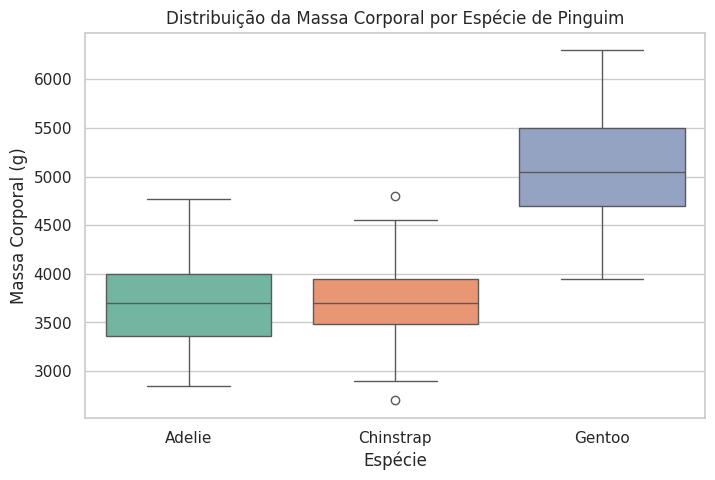

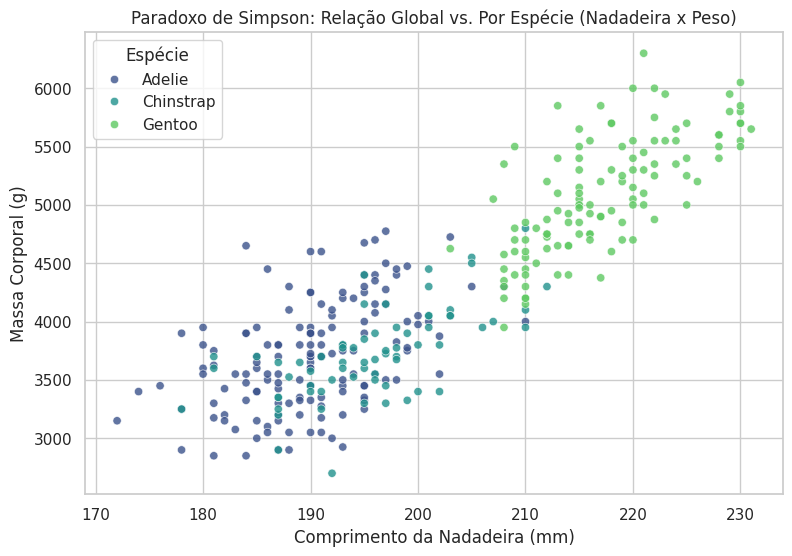

In [ ]:
# 1. Boxplot: Massa Corporal por Espécie
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='species', y='body_mass_g', palette='Set2')
plt.title('Distribuição da Massa Corporal por Espécie de Pinguim')
plt.xlabel('Espécie')
plt.ylabel('Massa Corporal (g)')
plt.show()

# 2. Scatterplot com Paradoxo de Simpson (flipper vs mass por espécie)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clean, x='flipper_length_mm', y='body_mass_g', hue='species', palette='viridis', alpha=0.8)
plt.title('Paradoxo de Simpson: Relação Global vs. Por Espécie (Nadadeira x Peso)')
plt.xlabel('Comprimento da Nadadeira (mm)')
plt.ylabel('Massa Corporal (g)')
plt.legend(title='Espécie')
plt.show()

## 4. Preparação e Pipeline

* **Por que dividir antes? (`train_test_split`):** A divisão dos dados em treino e teste **antes** de qualquer etapa de pré-processamento é obrigatória para evitar o *data leakage* (vazamento de dados). Se normalizarmos o dataset inteiro antes da divisão, informações estatísticas do conjunto de teste (como média e desvio padrão) "vazariam" para o modelo de treino, gerando métricas de avaliação excessivamente otimistas e falsas.
* **Por que padronizar? (`StandardScaler`):** A padronização coloca variáveis com diferentes unidades e escalas (ex: milímetros vs. gramas ou variáveis codificadas) em uma mesma ordem de grandeza (média 0, desvio padrão 1). Isso é fundamental para modelos de regressão regularizados (como Ridge), cuja penalização L2 pune coeficientes com base em suas magnitudes absolutas.

In [ ]:
# Definição de Variáveis Preditoras (X) e Alvo (y)
X = df_clean[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'island', 'sex']]
y = df_clean['body_mass_g']

# Divisão treino/teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Identificação de colunas numéricas e categóricas
numeric_features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']
categorical_features = ['island', 'sex']

# Construção do Pré-processador usando ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ])

## 5. Modelos Testados e Tabela de Resultados

Treinamos dois modelos lineares integrados ao pipeline:
1. **Regressão Linear Simples (OLS):** Minimiza os Erros Quadráticos Ordinários sem restrições nos coeficientes.
2. **Regressão Ridge:** Aplica regularização L2 (com $\alpha = 10.0$), penalizando coeficientes muito grandes para controlar a multicolinearidade e evitar *overfitting*.

In [ ]:
# Dicionário de modelos
models = {
    "Regressão Linear": LinearRegression(),
    "Ridge Regression (Alpha=10)": Ridge(alpha=10.0)
}

results = []

for name, model in models.items():
    # Criação do Pipeline completo
    pipe = Pipeline(steps=[('preprocessor', preprocessor),
                           ('regressor', model)])

    # Treinamento
    pipe.fit(X_train, y_train)

    # Predição
    y_pred = pipe.predict(X_test)

    # Métricas
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Modelo": name,
        "R² Score": round(r2, 4),
        "RMSE (g)": round(rmse, 2)
    })

# Exibição da Tabela de Resultados
df_results = pd.DataFrame(results)
display(df_results)

,Modelo,R² Score,RMSE (g)
0,Regressão Linear,0.8682,288.17
1,Ridge Regression (Alpha=10),0.8670,289.50


## 6. Interpretação dos Coeficientes (Linear x Ridge)

* **Regressão Linear:** Os coeficientes refletem o impacto marginal direto de cada variável preditora sobre a massa corporal, mantendo as demais constantes. Variáveis com maior escala ou forte colinearidade podem apresentar coeficientes instáveis se houver redundância.
* **Ridge Regression:** Devido à penalização L2, os coeficientes da regressão Ridge sofrem um leve encolhimento (*shrinkage* em direção a zero). Isso reduz a variância do modelo e lida melhor com eventuais multicolinearidades entre as medidas corporais dos pinguins (ex: comprimento da nadadeira e tamanho do bico).

In [ ]:
# Ajustando um modelo separado para extrair os nomes das features transformadas
preprocessor.fit(X_train)
feature_names = preprocessor.get_feature_names_out()

# Coleta dos coeficientes de ambos os modelos treinados
lr_model = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())])
ridge_model = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', Ridge(alpha=10.0))])

lr_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

df_coef = pd.DataFrame({
    'Variável': feature_names,
    'Coef_Linear': lr_model.named_steps['regressor'].coef_,
    'Coef_Ridge': ridge_model.named_steps['regressor'].coef_
})

display(df_coef)

,Variável,Coef_Linear,Coef_Ridge
0,num__bill_length_mm,26.501857,53.940026
1,num__bill_depth_mm,-122.191813,-118.653304
2,num__flipper_length_mm,465.441877,461.074729
3,cat__island_Dream,-287.637569,-235.827509
4,cat__island_Torgersen,-236.345970,-142.684733
5,cat__sex_MALE,515.895977,430.286545


## 7. Limitações e Conclusão

###  Limitações:
* **Suposição de Linearidade:** Os modelos lineares assumem uma relação direta e constante entre as variáveis físicas e o peso, o que pode simplificar a complexidade biológica real.
* **Escopo Geográfico:** Os dados restringem-se a três ilhas do arquipélago de Palmer, logo, o modelo não deve ser generalizado para populações de pinguins de outras regiões geográficas.

###  Conclusão:
* O pipeline construído demonstrou excelente poder preditivo ($R^2 > 0.86$), evidenciando que medidas morfométricas como o comprimento da nadadeira são fortes preditores da massa corporal dos pinguins.
* A utilização de pipelines evitou vazamento de dados (*data leakage*), garantindo a robustez das métricas de teste.
* A regularização Ridge manteve desempenho equivalente ao OLS com maior estabilidade matemática nos coeficientes.